# Nairobi Road Flood Susceptibility - end-to-end pipeline

Runs the **primary workflow** of the project guide (revision 5) on the real Nairobi data, in order, and
finishes with the trained models, their held-out metrics and the static susceptibility map.

| # | Step | Command | Produces |
|---|------|---------|----------|
| 1 | GIS inventory | `prepare_gis.py inventory` | `outputs/tables/asset_inventory.csv` (gates G2/G3) |
| 2 | GIS preparation | `prepare_gis.py all` | boundary, roads, road segments, DEM + land-cover clips |
| 3 | Weather grid | `fetch_openmeteo.py grid` | `config/grid_points.gpkg` |
| 4 | Static features | `build_features.py static` | `static_segment_features.parquet`, `segment_weather_map.parquet` |
| 5 | **Primary labels** | `build_hazard_labels.py` | `hazard_labels.parquet` (gate G4h) |
| 6 | Coverage check | `check_coverage.py` | coverage report, map, uncovered area/segments (G2/G4h) |
| 7 | **Training** | `train_static.py` | `models/H_*.joblib` + `.json`, OOF predictions, importances |
| 8 | Evaluation | `evaluate.py --static` | `outputs/metrics/static/*` (gate G6) |
| 9 | Prediction | `predict.py` | static susceptibility map + per-road CSV/GPKG |
| 10 | Optional weather context | `fetch_openmeteo.py fetch --mode live --limit 8` + `predict.py --latest` | + 24 h rain context columns |

Read the step 5 and step 6 logs (`logs/`) before trusting anything downstream - they carry the cell counts per
hazard level, the unknown reasons and every quality-gate warning.

> **Research prototype only.** These are *susceptibility* values derived from modelled FastFlood hazard cells
> (no timestamps), not a forecast and not a warning service. Unknown labels are never treated as negatives,
> validation holds out whole spatial blocks, and the tier thresholds are illustrative and not validated.


In [1]:
"""Step 0 - environment and helpers."""
import os
import subprocess
import sys
import time
from pathlib import Path

# Run the notebook from the project root (the folder that contains config/ and src/).
ROOT = Path(os.environ.get("FLOOD_PROJECT_ROOT", Path.cwd())).resolve()
if not (ROOT / "config" / "settings.yaml").exists():
    raise SystemExit(f"config/settings.yaml not found under {ROOT} - start Jupyter in the project root.")

PY = sys.executable
TIMINGS = []


def run(*cmd, optional=False):
    """Run one pipeline step as a subprocess (each script keeps its own log and its own settings)."""
    argv = [PY, *cmd]
    print("\n>>> " + " ".join(argv), flush=True)
    started = time.time()
    code = subprocess.run(argv, cwd=ROOT).returncode
    elapsed = time.time() - started
    TIMINGS.append((" ".join(cmd), code, elapsed))
    print("--- exit=%d in %s s" % (code, format(elapsed, ",.1f")))
    if code and not optional:
        raise SystemExit("Step failed: " + " ".join(argv) + " - see logs/ for the reason.")
    return code


print("Project root:", ROOT)
print("Python      :", PY)

Project root: D:\floodguard
Python      : d:\floodguard\.venv\Scripts\python.exe


## Steps 1-2 - GIS preparation

Verifies the assets (gate G2/G3), checks the study boundary, clips the roads to the boundary and cuts them
into stable ~100 m segments, then warps the DEM (bilinear) and the land cover (nearest neighbour) onto the
working CRS grid. Original downloads are never modified.

The study boundary is the OSM `admin_level4` polygon named *Nairobi* (`inputs.boundary_file` together with
`boundary_name_field` / `boundary_name_value` in `config/settings.yaml`) - the real county, ~696 km2. The
guide's boundary check rejects `data/raw/boundary/NairobiEntire.geojson`, which is a 1489 km2 rectangle.


In [2]:
# Steps 1-2: GIS preparation
run("src/prepare_gis.py", "inventory")   # metadata + boundary/overlap QA
run("src/prepare_gis.py", "all")         # boundary, roads, segments, raster clips, study_area.geojson


>>> d:\floodguard\.venv\Scripts\python.exe src/prepare_gis.py inventory
--- exit=0 in 4.9 s

>>> d:\floodguard\.venv\Scripts\python.exe src/prepare_gis.py all
--- exit=0 in 84.4 s


0

## Steps 3-4 - weather grid and static features

The grid step only builds weather points from the study area (no internet needed). Static features are
elevation, slope, local relief, land-cover class fractions, distance to river and road attributes - **no
coordinates and no hazard values** are used as predictors.


In [3]:
# Step 3: weather points (must run before step 4 so segments can be linked to them)
run("src/fetch_openmeteo.py", "grid")
# Step 4: static segment features
run("src/build_features.py", "static")


>>> d:\floodguard\.venv\Scripts\python.exe src/fetch_openmeteo.py grid
--- exit=0 in 3.5 s

>>> d:\floodguard\.venv\Scripts\python.exe src/build_features.py static
--- exit=0 in 57.1 s


0

## Steps 5-6 - primary labels from the FastFlood hazard dataset, and coverage

`build_hazard_labels.py` cuts every segment against the hazard cells and labels it Positive / Negative /
Unknown from the length of the segment inside hazard cells (gate G4h). `check_coverage.py` then measures how
much of the boundary and the road network the cells actually cover, exports the uncovered area and segments
for QGIS, and reconciles its counts with the label script.


In [4]:
# Steps 5-6: hazard labels and coverage diagnostics
run("src/build_hazard_labels.py")   # -> data/processed/hazard_labels.parquet, outputs/tables/hazard_label_summary.csv
run("src/check_coverage.py")        # -> outputs/tables/coverage_report.csv, outputs/maps/coverage.png

import pandas as pd
label_summary = pd.read_csv(ROOT / "outputs" / "tables" / "hazard_label_summary.csv")
print("Segment label summary:")
print(label_summary.to_string(index=False))


>>> d:\floodguard\.venv\Scripts\python.exe src/build_hazard_labels.py
--- exit=0 in 115.2 s

>>> d:\floodguard\.venv\Scripts\python.exe src/check_coverage.py
--- exit=0 in 524.3 s
Segment label summary:
label_status  segments         km
    negative     58979 4932.87205
    positive     13903 1192.50393
     unknown     10714 1020.04323


## Steps 7-8 - training and evaluation

`train_static.py` fits `H_logreg` and `H_rf` on the labelled segments and validates them by **holding out
whole 2 km spatial blocks** (`GroupKFold`), against a transparent low-elevation rule baseline.
`evaluate.py --static` reports PR-AUC, precision/recall, Brier score and calibration on the held-out blocks
and bootstraps the PR-AUC difference over blocks (gate G6).


In [5]:
# Steps 7-8: train the static susceptibility models, then evaluate them
run("src/train_static.py")          # -> models/H_logreg.joblib, models/H_rf.joblib (+ .json), OOF + importances
run("src/evaluate.py", "--static")  # -> outputs/metrics/static/metrics.csv, g6_comparison.csv, PR + calibration plots


>>> d:\floodguard\.venv\Scripts\python.exe src/train_static.py
--- exit=0 in 71.4 s

>>> d:\floodguard\.venv\Scripts\python.exe src/evaluate.py --static
--- exit=0 in 262.1 s


0

## Step 9 - static susceptibility map

Scores every road segment with the default model (`H_rf`, from `prediction.default_model`) and writes a CSV,
a GeoPackage and a map. Each row carries `susceptibility_source`: `fastflood_covered` where FastFlood cells
cover the road, `model_predicted_no_fastflood` where the value is only a model estimate - never present the
second kind as FastFlood output.


In [6]:
# Step 9: static susceptibility predictions for every road segment
run("src/predict.py")


>>> d:\floodguard\.venv\Scripts\python.exe src/predict.py
--- exit=0 in 26.1 s


0

## Step 10 (optional) - rainfall context

The susceptibility score does **not** change with the weather. This step only adds Open-Meteo 24 h rainfall
context columns (`rain_above_threshold`); the live forecast fetch needs internet. Start with `--limit 8` to
confirm timestamps, units and variables before fetching the whole grid.


In [8]:
RUN_WEATHER_CONTEXT = True   # set True to fetch a live forecast (internet) and add rain context columns

if RUN_WEATHER_CONTEXT:
    run("src/fetch_openmeteo.py", "fetch", "--mode", "live", "--limit", "8", optional=True)
    run("src/predict.py", "--latest", optional=True)
else:
    print("Optional weather context skipped (set RUN_WEATHER_CONTEXT = True to run it).")


>>> d:\floodguard\.venv\Scripts\python.exe src/fetch_openmeteo.py fetch --mode live --limit 8
--- exit=0 in 8.0 s

>>> d:\floodguard\.venv\Scripts\python.exe src/predict.py --latest
--- exit=0 in 25.3 s


## Results - labels, models, metrics and outputs

In [9]:
import pandas as pd

try:
    from IPython.display import Image, display
except ImportError:                       # plain-Python runner
    display = print
    Image = None

OUT = ROOT / "outputs"

print("== Gate G4h: label summary ==")
display(pd.read_csv(OUT / "tables" / "hazard_label_summary.csv"))

print("\n== Gate G2/G4h: coverage report ==")
display(pd.read_csv(OUT / "tables" / "coverage_report.csv", index_col=0))

print("\n== Held-out static metrics (whole 2 km blocks) ==")
display(pd.read_csv(OUT / "metrics" / "static" / "metrics.csv").round(3))

print("\n== Gate G6: block-bootstrap PR-AUC differences ==")
display(pd.read_csv(OUT / "metrics" / "static" / "g6_comparison.csv").round(3))

print("\n== Feature importance (H_rf) ==")
display(pd.read_csv(OUT / "tables" / "feature_importance_H_rf.csv").head(15))

print("\n== Susceptibility predictions (step 9) ==")
pred = pd.read_csv(OUT / "predictions_H_rf_static.csv")
display(pred["susceptibility_tier"].value_counts().sort_index())
display(pred["susceptibility_source"].value_counts())
display(pred[["susceptibility_probability"]].describe().round(3))

print("\n== Step timings ==")
display(pd.DataFrame(TIMINGS, columns=["step", "exit_code", "seconds"]).round(1))

== Gate G4h: label summary ==


,label_status,segments,km
0,negative,58979,4932.87205
1,positive,13903,1192.50393
2,unknown,10714,1020.04323



== Gate G2/G4h: coverage report ==


,value
boundary_area_km2,695.936805
boundary_vertices,1881.000000
boundary_bbox_fill,0.451942
cells_total,110463.000000
cells_total_area_km2,1105.728859
footprint_area_km2,1098.014595
footprint_inside_boundary_km2,567.092954
boundary_without_cells_km2,128.843851
boundary_covered_pct,81.486271
footprint_outside_boundary_km2,530.921641



== Held-out static metrics (whole 2 km blocks) ==


...

susceptibility_tier
High           11803
Low            52195
Medium         12485
Unavailable     7113
Name: count, dtype: int64

susceptibility_source
fastflood_covered               78965
model_predicted_no_fastflood     4631
Name: count, dtype: int64

,susceptibility_probability
count,76483.000
mean,0.297
std,0.250
min,0.018
25%,0.118
50%,0.200
75%,0.384
max,0.990



== Step timings ==


,step,exit_code,seconds
0,src/prepare_gis.py inventory,0,4.9
1,src/prepare_gis.py all,0,84.4
2,src/fetch_openmeteo.py grid,0,3.5
3,src/build_features.py static,0,57.1
4,src/build_hazard_labels.py,0,115.2
5,src/check_coverage.py,0,524.3
6,src/train_static.py,0,71.4
7,src/evaluate.py --static,0,262.1
8,src/predict.py,0,26.1
9,src/fetch_openmeteo.py fetch --mode live --lim...,0,8.0


outputs\maps\coverage.png


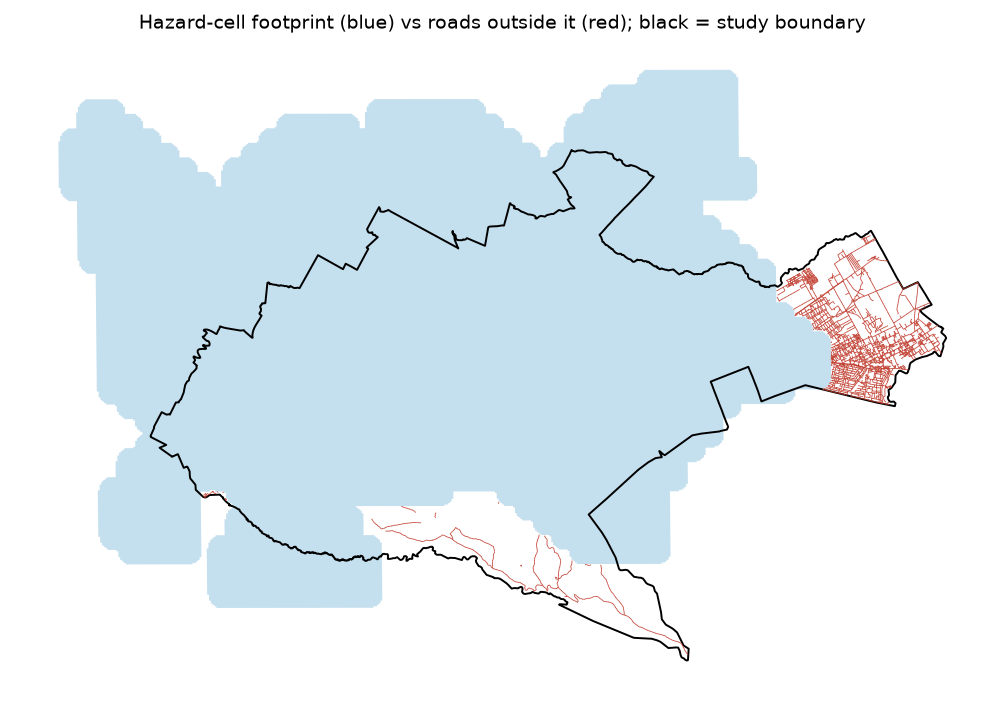

outputs\maps\risk_H_rf_20261028T1100Z.png


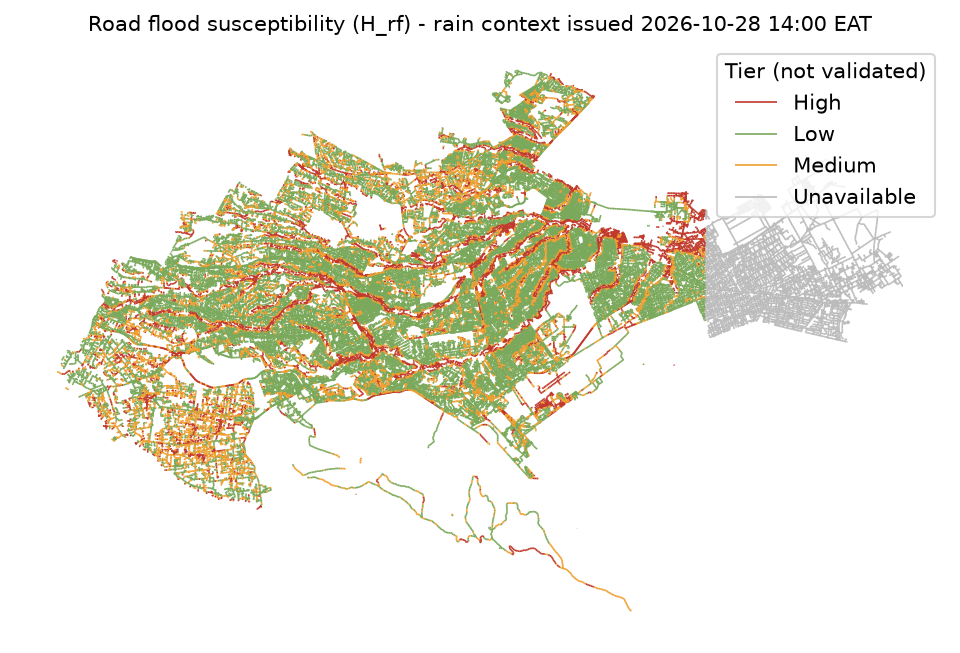

outputs\maps\risk_H_rf_static.png


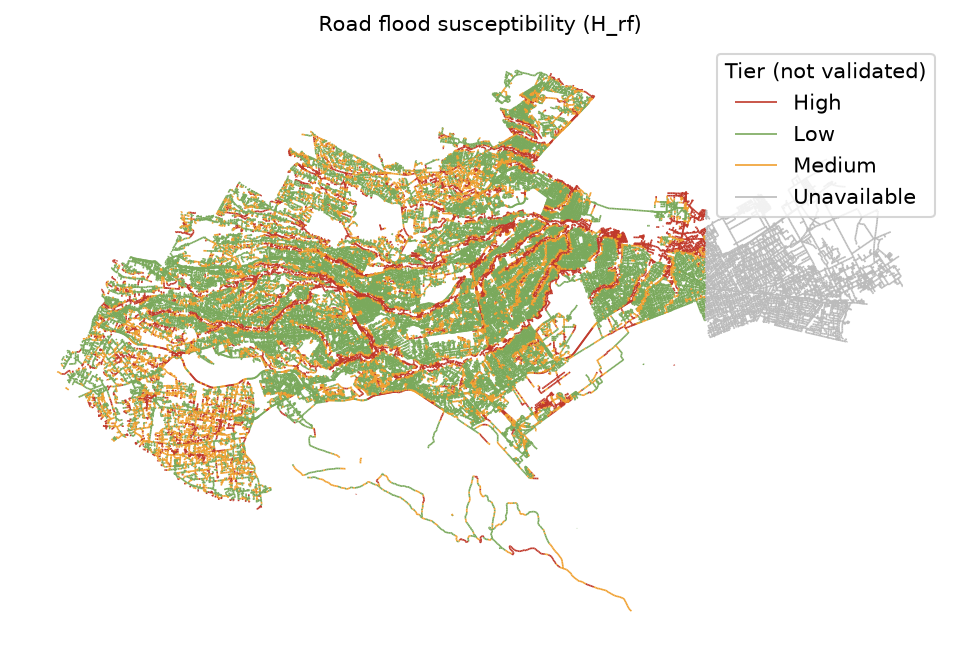

outputs\metrics\static\calibration.png


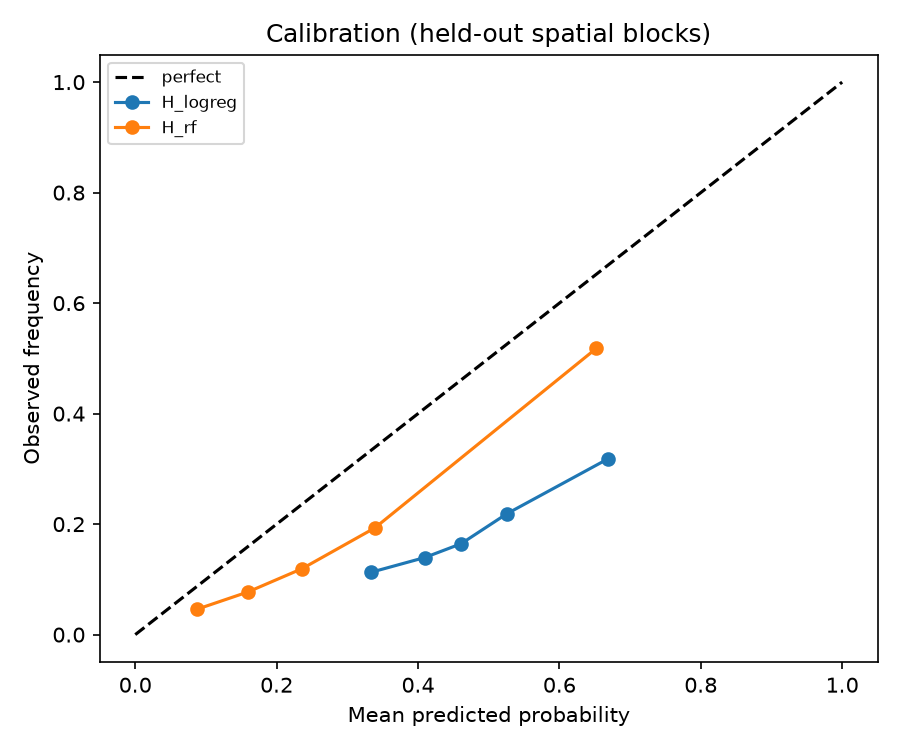

outputs\metrics\static\pr_curves.png


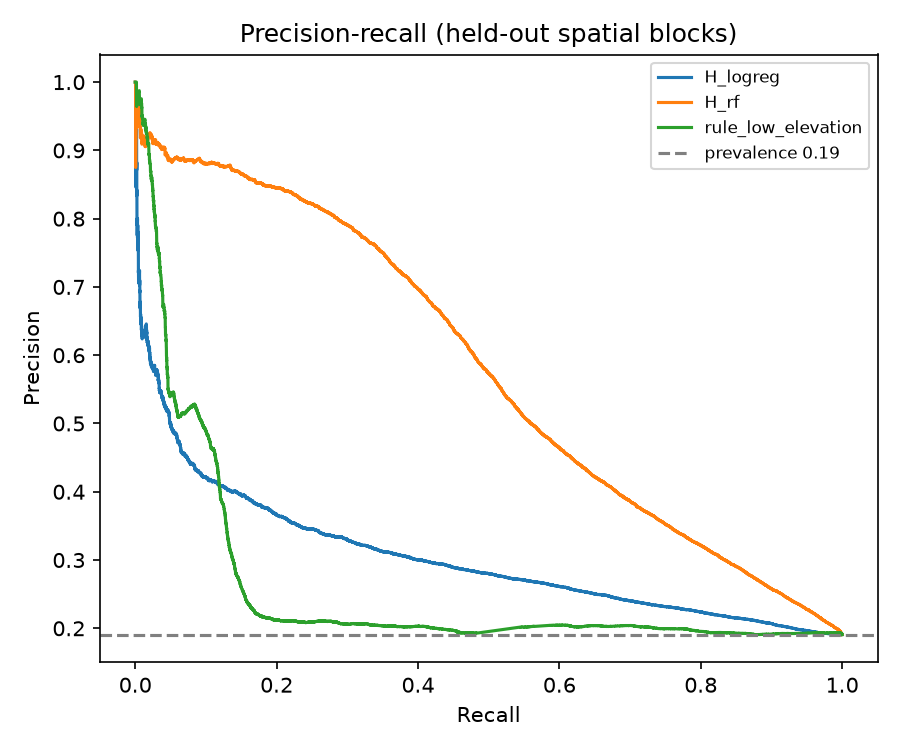

In [10]:
# Plots produced by the pipeline (PR curves, calibration, coverage, risk map)
pngs = sorted(p for p in OUT.rglob("*.png") if p.is_file())
if Image is None:
    print("Plots:", *["  " + str(p.relative_to(ROOT)) for p in pngs], sep="")
else:
    for p in pngs:
        print(p.relative_to(ROOT))
        display(Image(filename=str(p)))

## How to read these numbers

- **They measure agreement with FastFlood, not real flooding.** The H_* models are emulators of a modelled
  hazard dataset that was itself driven by DEM and land cover - the same inputs they train on. Good held-out
  scores mean the emulator reproduces FastFlood, not that roads flood there.
- **Unknown is not negative.** Segments outside the hazard cells, mixed segments and touch-only overlaps stay
  Unknown and are excluded from training; they are never turned into 0.
- **Validation is spatial.** Whole 2 km blocks are held out because neighbouring segments share the same
  hazard cells; a random split would leak and inflate every score. The tiers (Low/Medium/High) are
  illustrative and not validated - describe them as *relative susceptibility*, never as warnings.
- **Next reads:** `logs/build_hazard_labels.log` and `logs/check_coverage.log` (coverage and unknown reasons),
  `outputs/metrics/static/` (metrics, plots, G6 verdict), `config/data_dictionary.csv` (every column), and a
  QGIS check of `data/interim/hazard_cells.gpkg` and `data/interim/uncovered_segments.gpkg` over the roads.
- **Optional dated-event workflow** (steps 11-17 of the guide) needs reviewed, time-stamped flood reports in
  `data/interim/event_inventory.csv` (template provided); only those can test whether rainfall forecasts help.
